# Bloque 4. Construcción de la serie temporal

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/04_series_temporales.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 1, tarde (unos 90 minutos).

Hasta ahora trabajaste con **una** imagen. Una serie temporal es lo mismo repetido en el tiempo: el valor de una variable en un punto, fecha tras fecha. En este bloque construyes esa serie desde cero con Sentinel-2, la guardas con sus metadatos (el momento FAIR del día) y la miras.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | De una imagen a una serie: revisita y nubes | 15 |
| 2 | Los puntos de muestreo (CSV) y su mapa | 15 |
| 3 | Búsqueda y carga de ventanas pequeñas (patrón nativo) | 20 |
| 4 | Máscara SCL, reflectancia e índices, paso a paso | 10 |
| 5 | La serie de todos los puntos | 5 |
| 6 | Filtro de escena frente a máscara SCL: lo medimos | 10 |
| 7 | Guardar en parquet con metadatos (FAIR) | 5 |
| 8 | La serie de 12 meses de respaldo y su gráfico | 10 |

Seguimos el **patrón nativo** del curso: la búsqueda (`pystac_client`) y la carga (`odc.stac.load`) las escribes tú. Los helpers de `utils/` solo **preparan** sus argumentos y ordenan los datos antes y después.

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). La siguiente instala los paquetes de STAC que Colab no trae, solo si faltan.

In [1]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [2]:
# @title Instalar los paquetes de este bloque (solo si faltan)
import importlib.util

# Paquete de requirements.txt -> nombre con el que se importa
NECESARIOS = {"pystac-client": "pystac_client", "planetary-computer": "planetary_computer",
              "odc-stac": "odc.stac", "rioxarray": "rioxarray"}
requisitos = [linea.strip() for linea in (RAIZ / "talleres/fair-series-temporales/requirements.txt").read_text().splitlines()
              if linea.strip() and not linea.startswith("#")]
requisitos = [r for r in requisitos if r.split()[0] in NECESARIOS]

if any(importlib.util.find_spec(modulo) is None for modulo in NECESARIOS.values()):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requisitos], check=True)
    print("Instalado:", ", ".join(requisitos))
else:
    print("Ya está todo instalado:", ", ".join(NECESARIOS))

Ya está todo instalado: pystac-client, planetary-computer, odc-stac, rioxarray


In [3]:
# @title Importar bibliotecas
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import odc.stac
import pandas as pd
import planetary_computer
import plotly.express as px
import pyarrow.parquet as pq
import pystac_client
import xarray as xr
from matplotlib.colors import ListedColormap
from shapely.geometry import box, shape

# Funciones de apoyo del curso (carpeta utils/)
from utils.series import (agregar_nubes_escena, bbox_punto, bbox_puntos, cargar_puntos_csv, cargar_ventanas,
                          construir_series, crs_utm, guardar_series, resumen_validez)
from utils.stac import parametros_busqueda, parametros_carga, preparar_items, resumir_imagenes
from utils.viz import mapa_puntos

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de GDAL por escenas sin georreferencia

# Una paleta distinguible con daltonismo (Okabe-Ito), una por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

## Dos funciones para pasar de DN a reflectancia

En el bloque 3 convertiste a mano una imagen: `reflectancia = DN * 0,0001 + offset`, con el offset según el baseline de la imagen. Aquí hay muchas fechas, cada una con su baseline, así que dejamos esos pasos en dos funciones **escritas aquí**, para que puedas leerlas (y cambiarlas). Sirven solo para Sentinel-2 de Planetary Computer.

In [4]:
def agregar_offset(datos, items):
    # El offset depende del baseline de procesamiento de cada imagen, que está en sus metadatos:
    # baseline 04.00 o posterior -> -0.1 (a los DN se les sumaron 1000); anterior -> 0
    offset_por_fecha = {}
    for item in items:
        fecha = np.datetime64(item.datetime.replace(tzinfo=None), "ns")
        baseline = float(item.properties["s2:processing_baseline"])  # "05.11" -> 5.11
        offset_por_fecha[fecha] = -0.1 if baseline >= 4.0 else 0.0
    # La fecha de cada capa de `datos` es la de la primera imagen de su grupo: ahí buscamos su offset
    offsets = [offset_por_fecha[fecha] for fecha in datos["time"].values.astype("datetime64[ns]")]
    return datos.assign_coords(offset_reflectancia=("time", offsets))


def reflectancia_sentinel2(datos):
    # Convierte antes de combinar fechas (por ejemplo antes de .median("time")): después ya no hay un offset por fecha
    # reflectancia = DN * 0.0001 + offset de cada fecha (el DN 0 significa "sin dato")
    refl = datos.where(datos != 0) * 0.0001 + datos["offset_reflectancia"]
    # Una reflectancia válida está entre 0 y 1: lo demás pasa a NaN
    refl = refl.where((refl >= 0) & (refl <= 1))
    return refl.drop_vars("offset_reflectancia")

## 1. De una imagen a una serie temporal

Tres ideas explican casi todo lo que viene.

**Revisita.** Sentinel-2 vuelve a pasar por el mismo lugar cada pocos días (con tres satélites en órbita y escenas que se traslapan, en Concepción hay una toma cada dos o tres días). Cada toma es una **fecha** de la serie. Las fechas no son regulares ni diarias, y eso importa al calcular promedios móviles (bloque 5).

**Nubes.** Una serie con nubes mezcladas es una serie equivocada: una nube es blanca y hace que el agua parezca otra cosa. Hay dos formas de tratarlas, y no hacen lo mismo:

| | Filtro de escena (`eo:cloud_cover`) | Máscara de píxel (banda SCL) |
|---|---|---|
| Dónde actúa | En la búsqueda STAC, antes de cargar | Después de cargar, píxel por píxel |
| Qué descarta | Fechas completas | Píxeles con nube, sombra, cirrus, saturados o sin dato |
| Qué sabe de tu punto | Nada: es el porcentaje de **toda la escena** (unos 100 x 100 km) | Todo: mira justo tus píxeles |
| Costo | Ahorra datos descargados | Hay que cargar la fecha para poder juzgarla |

Más abajo medimos cuánto cambia cada una en nuestros puntos.

**Puntos y ventanas.** Cargar el área completa que encierra todos los puntos es mucho más pesado que cargar una **ventana pequeña** (unos 300 x 300 m) alrededor de cada uno. Para series en puntos, la ventana alcanza: de cada fecha resumimos sus píxeles con la mediana, que resiste algún píxel raro.

## 2. Los puntos de muestreo

Los puntos están en un archivo CSV con las columnas `id, nombre, lat, lon, tipo`. `cargar_puntos_csv` lo lee y valida (columnas, `id` únicos, rangos de latitud y longitud). Un nombre simple busca el archivo en la carpeta `datos/` del taller.

In [5]:
puntos = cargar_puntos_csv("puntos_rapa_nui.csv")
puntos

,id,nombre,lat,lon,tipo
0,pto_buceo,Centro de Buceo,-27.154090,-109.439317,puerto
1,hanga_nui,Hanga Nui,-27.126574,-109.275320,rompiente
2,playa_anakena,Playa Anakena,-27.072825,-109.323381,playa
3,bahía_perouse,Bahía de La Pérouse,-27.087642,-109.297931,bahía
4,vinapu,Vinapu,-27.174149,-109.403995,rompiente
5,ovahe,Ovahe,-27.073960,-109.313736,playa


Seis puntos, una bahía (Bahía de La Pérouse), un puerto (Centro de Buceo), dos zonas de rompiente (Hanga Nui y Vinapu) y dos playa (Ovahe y Playa Anakena).

In [6]:
mapa_puntos(puntos, radio_m=150)

## 3. Búsqueda y carga de ventanas pequeñas

Usamos un **período de tres años**, (enero del 2023 a enero de 2026). Más adelante cargamos la serie de 12 meses, que ya está preparada.

### 3.1 Búsqueda (nativa)

Hacemos **una sola búsqueda para toda la zona**: `bbox_puntos` entrega el rectángulo que contiene las ventanas de todos los puntos. Después, cada punto se queda con las imágenes que lo tocan (una escena puede cubrir unos puntos y otros no). Pedimos hasta 100 % de nubes a propósito: así podemos comparar después distintos filtros de escena con una sola carga.

In [9]:
FECHAS = ("2023-01-01", "2026-01-01")
RADIO_M = 150  # ventana de unos 300 x 300 m alrededor de cada punto

bbox = bbox_puntos(puntos, RADIO_M)
print("bbox de la zona (oeste, sur, este, norte):", [round(c, 3) for c in bbox])

# Catálogo STAC de Planetary Computer; `sign_inplace` firma los enlaces de descarga de cada imagen
catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
parametros = parametros_busqueda("sentinel-2", bbox, FECHAS, nubes_max=100, catalogo=catalogo)
busqueda = catalogo.search(**parametros)  # llamada nativa de pystac_client
items = busqueda.item_collection()
items = preparar_items(items)  # sin versiones duplicadas y de un solo catálogo
print(f"{len(items)} imágenes (escenas) entre {FECHAS[0]} y {FECHAS[1]}")

# conectar a un servidor de imágenes satelitales en la nube (Planetary Computer)
# buscar todas las imágenes disponibles de Sentinel-2 que cubren los puntos dentro del periodo

bbox de la zona (oeste, sur, este, norte): [-109.441, -27.175, -109.274, -27.071]
Se encontraron 432 imágenes (sentinel-2-l2a, planetary) (56 versiones repetidas descartadas).
432 imágenes (escenas) entre 2023-01-01 y 2026-01-01


Cada fila es una escena (un *tile* en una fecha). Dos tiles contiguos (T18HXD y T18HXE) tomados el mismo día son dos imágenes, pero para el mismo punto solo una de ellas lo cubre. Fíjate en el baseline y el offset: el offset de reflectancia depende de la versión de procesamiento de **cada** imagen y no se fija a mano (bloque 2).

In [10]:
tabla_items = resumir_imagenes(items)
print(tabla_items.head(8).to_string())
print("\nBaselines:", tabla_items["baseline"].value_counts().to_dict(), "| offsets:", tabla_items["offset"].value_counts().to_dict())

        fecha    nubes_%                                                      id baseline  offset
0  2023-01-01  24.906223  S2B_MSIL2A_20230101T173119_R069_T12JXQ_20230102T045042    04.00    -0.1
1  2023-01-01   6.946093  S2B_MSIL2A_20230101T173119_R069_T12JXR_20230102T061425    04.00    -0.1
2  2023-01-06   5.107271  S2A_MSIL2A_20230106T173121_R069_T12JXQ_20230107T050319    04.00    -0.1
3  2023-01-06  17.927060  S2A_MSIL2A_20230106T173121_R069_T12JXR_20230107T051639    04.00    -0.1
4  2023-01-11  23.603657  S2B_MSIL2A_20230111T173119_R069_T12JXQ_20230112T094112    04.00    -0.1
5  2023-01-11  42.050928  S2B_MSIL2A_20230111T173119_R069_T12JXR_20230112T091916    04.00    -0.1
6  2023-01-16  14.679806  S2A_MSIL2A_20230116T173121_R069_T12JXQ_20230117T023424    04.00    -0.1
7  2023-01-16   1.441644  S2A_MSIL2A_20230116T173121_R069_T12JXR_20230117T014512    04.00    -0.1

Baselines: {'05.11': 207, '05.10': 143, '05.09': 66, '04.00': 16} | offsets: {-0.1: 432}


¿Cuántas imágenes nos quedarían con cada límite de nubes de escena? Ese filtro actúa en la búsqueda y es lo más barato, pero recuerda que dice algo de toda la escena, no de tu punto.

In [11]:
nubes = tabla_items["nubes_%"]
print(pd.Series({f"nubes <= {limite} %": int((nubes <= limite).sum()) for limite in (10, 30, 60, 100)}).to_string())

nubes <= 10 %      97
nubes <= 30 %     204
nubes <= 60 %     304
nubes <= 100 %    432


### 3.2 Carga de una ventana (nativa), a la vista

Primero un solo punto, con cada paso escrito. La carga de `odc.stac.load` es **perezosa**: arma el cubo pero todavía no lee píxeles. Así vemos su tamaño antes de pagar el tiempo de la lectura.

In [12]:
punto = puntos.loc[puntos["id"] == "playa_anakena"].iloc[0]
bbox_p = bbox_punto(punto["lon"], punto["lat"], RADIO_M)  # ventana de unos 300 x 300 m
# Solo las escenas cuya huella toca la ventana (una escena puede cubrir unos puntos y otros no)
ventana_p = box(*bbox_p)
items_p = [item for item in items if shape(item.geometry).intersects(ventana_p)]
bandas = ["B03", "B04", "B05", "B08", "SCL"]  # verde, rojo, borde rojo, NIR y la banda de clasificación (SCL)
print("Bandas:", bandas)

parametros_ds = parametros_carga("sentinel-2", bandas, resolucion=10, crs=crs_utm(punto["lon"], punto["lat"]),
                                 catalogo=catalogo, bbox=bbox_p, chunks={"x": 512, "y": 512}, fail_on_error=False)
datos_p = odc.stac.load(items_p, **parametros_ds)  # llamada nativa de odc.stac (perezosa)
datos_p = agregar_offset(datos_p, items_p)  # offset de reflectancia de cada fecha (la función de arriba)
datos_p = agregar_nubes_escena(datos_p, items_p)  # % de nubes de la escena de cada fecha
print(f"{len(items_p)} imágenes -> {datos_p.sizes['time']} fechas, ventana de {datos_p.sizes['x']} x {datos_p.sizes['y']} píxeles")
print(f"Tamaño del cubo de este punto: {datos_p.nbytes / 1e6:.1f} MB (todavía sin leer)")
datos_p

#resumen con el número de imágenes, las dimensiones de la ventana en píxeles y el tamaño estimado en megabytes que ocupará el cubo de datos de ese punto

Bandas: ['B03', 'B04', 'B05', 'B08', 'SCL']
216 imágenes -> 214 fechas, ventana de 31 x 31 píxeles
Tamaño del cubo de este punto: 4.1 MB (todavía sin leer)


<xarray.Dataset> Size: 4MB
Dimensions:              (y: 31, x: 31, time: 214)
Coordinates:
  * y                    (y) float64 248B 7.005e+06 7.005e+06 ... 7.004e+06
  * x                    (x) float64 248B 6.661e+05 6.661e+05 ... 6.664e+05
  * time                 (time) datetime64[ns] 2kB 2023-01-01T17:31:19.024000...
    offset_reflectancia  (time) float64 2kB -0.1 -0.1 -0.1 ... -0.1 -0.1 -0.1
    nubes_escena         (time) float64 2kB 6.946 17.93 42.05 ... 64.62 13.55
    spatial_ref          int32 4B 32712
Data variables:
    B03                  (time, y, x) float32 823kB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B04                  (time, y, x) float32 823kB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B05                  (time, y, x) float32 823kB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    B08                  (time, y, x) float32 823kB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>
    SCL                  (time, y, x) float32 823kB dask.array<chunksize=(1, 31, 31), meta=np.ndarray>

Compara con lo que pesaría cargar **toda la caja** que contiene los seis puntos, con las mismas bandas y fechas. Es solo una cuenta (ancho x alto de la caja en píxeles de 10 m):

In [13]:
lat_media = (bbox[1] + bbox[3]) / 2
ancho_m = (bbox[2] - bbox[0]) * 111_320 * math.cos(math.radians(lat_media))
alto_m = (bbox[3] - bbox[1]) * 111_320
pixeles_caja = (ancho_m / 10) * (alto_m / 10)
gb_caja = pixeles_caja * len(bandas) * datos_p.sizes["time"] * 4 / 1e9
mb_ventanas = len(puntos) * datos_p.nbytes / 1e6
print(f"Caja completa ({ancho_m / 1000:.0f} x {alto_m / 1000:.0f} km): unos {gb_caja:.0f} GB")
print(f"Seis ventanas de 300 x 300 m: unos {mb_ventanas:.0f} MB")


Caja completa (17 x 12 km): unos 8 GB
Seis ventanas de 300 x 300 m: unos 25 MB


Por eso cargamos ventanas. `cargar_ventanas` repite para **cada** punto los pasos que acabas de ver (`bbox_punto`, el filtro de escenas con `shape(...).intersects`, `parametros_carga`, `odc.stac.load`, `agregar_offset`, `agregar_nubes_escena`; usa la versión de `utils`, que hace lo mismo que la tuya) y al final lee todos los píxeles de una vez, en paralelo. Lanza la celda y espera un par de minutos: es la lectura de red de las seis ventanas.

> En una prueba anterior (otra zona) las ventanas tardaron 78 s con 313 MB y la caja completa 306 s. Con los puntos de este taller, la lectura de tres meses la medimos más abajo en esta misma celda.

In [14]:
inicio = time.time()
ventanas = cargar_ventanas(items, puntos, radio_m=RADIO_M, catalogo=catalogo)  # dict {id del punto: Dataset}
print(f"Carga total (incluye armar el cubo de cada punto): {time.time() - inicio:.0f} s")

#ejecuta la descarga y armado real de los datos

pto_buceo: 432 imágenes, 215 fechas, ventana de 31 x 31 píxeles
hanga_nui: 432 imágenes, 215 fechas, ventana de 31 x 31 píxeles
playa_anakena: 216 imágenes, 214 fechas, ventana de 31 x 31 píxeles
bahía_perouse: 216 imágenes, 214 fechas, ventana de 31 x 31 píxeles
vinapu: 432 imágenes, 215 fechas, ventana de 31 x 32 píxeles
ovahe: 216 imágenes, 214 fechas, ventana de 31 x 31 píxeles
Lectura terminada: 25 MB en 375 s.
Carga total (incluye armar el cubo de cada punto): 384 s


`ventanas` es un diccionario con un Dataset por punto, con los valores **en números digitales (DN)**, sin enmascarar ni convertir. Cada Dataset trae las coordenadas `offset_reflectancia` y `nubes_escena`, una por fecha.

In [15]:
ventana = ventanas["playa_anakena"]
print(ventana)
print("\nPrimeras fechas con su offset y las nubes de su escena:")
print(ventana[["offset_reflectancia", "nubes_escena"]].to_dataframe().head(5).to_string())

#explorar y verificar el contenido del cubo de datos para Playa Anakena

<xarray.Dataset> Size: 4MB
Dimensions:              (y: 31, x: 31, time: 214)
Coordinates:
  * y                    (y) float64 248B 7.005e+06 7.005e+06 ... 7.004e+06
  * x                    (x) float64 248B 6.661e+05 6.661e+05 ... 6.664e+05
  * time                 (time) datetime64[ns] 2kB 2023-01-01T17:31:19.024000...
    offset_reflectancia  (time) float64 2kB -0.1 -0.1 -0.1 ... -0.1 -0.1 -0.1
    nubes_escena         (time) float64 2kB 6.946 17.93 42.05 ... 64.62 13.55
    spatial_ref          int32 4B 32712
Data variables:
    B03                  (time, y, x) float32 823kB 1.944e+03 ... 2.388e+03
    B04                  (time, y, x) float32 823kB 1.634e+03 ... 2.64e+03
    B05                  (time, y, x) float32 823kB 1.645e+03 ... 3.225e+03
    B08                  (time, y, x) float32 823kB 1.666e+03 ... 4.272e+03
    SCL                  (time, y, x) float32 823kB 6.0 6.0 6.0 ... 5.0 5.0 5.0

Primeras fechas con su offset y las nubes de su escena:
                        

## 4. Máscara SCL, reflectancia e índices, paso a paso

Antes de usar `construir_series`, hacemos a mano los tres pasos para un punto.

**Paso 1: la máscara SCL.** La banda SCL (*Scene Classification Layer*) asigna a cada píxel una clase (un número entero). La máscara es una pregunta por píxel: ¿su clase está en la lista de clases que descartamos? Con `isin` obtienes un valor `True` donde la respuesta es sí, y con `~` (negación) lo inviertes para quedarte con los píxeles válidos. Estas son las clases que importan (la última columna marca las que descartamos, las mismas que `construir_series` descarta por defecto):

| Código | Clase | ¿Se descarta por defecto? |
|---|---|---|
| 0 | sin datos | sí |
| 1 | saturado | sí |
| 2 | áreas oscuras | no |
| 3 | sombra de nube | sí |
| 4 | vegetación | no |
| 5 | suelo desnudo | no |
| 6 | agua | no |
| 7 | nube de probabilidad baja o sin clasificar | no |
| 8 | nube de probabilidad media | sí |
| 9 | nube de probabilidad alta | sí |
| 10 | cirrus | sí |
| 11 | nieve o hielo | no |

Miremos qué clases hay en las ventanas de nuestros puntos (porcentaje de los píxeles de las 39 fechas, con nubes de hasta 100 % en la escena):

In [16]:
clases = {0: "sin datos", 1: "saturado", 2: "áreas oscuras", 3: "sombra de nube", 4: "vegetación", 5: "suelo desnudo",
          6: "agua", 7: "nube prob. baja", 8: "nube prob. media", 9: "nube prob. alta", 10: "cirrus", 11: "nieve"}
conteo = {}
for id_punto, datos in ventanas.items():
    scl = datos["SCL"].values
    scl = scl[~np.isnan(scl)].astype(int)
    conteo[id_punto] = pd.Series(scl).value_counts(normalize=True).mul(100)
distribucion = pd.DataFrame(conteo).rename(index=clases).fillna(0).round(1)
distribucion.loc[distribucion.sum(axis=1) > 0]

,pto_buceo,hanga_nui,playa_anakena,bahía_perouse,vinapu,ovahe
áreas oscuras,0.2,0.0,0.0,0.0,1.2,0.0
sombra de nube,14.5,15.8,11.0,8.7,26.6,12.5
vegetación,8.9,6.2,8.6,11.9,6.6,7.9
suelo desnudo,6.2,11.0,9.1,6.9,6.1,14.6
agua,19.9,12.3,20.5,24.9,8.6,14.3
nube prob. baja,1.3,8.0,1.3,1.4,3.3,3.5
nube prob. media,13.4,14.5,13.5,11.7,16.0,13.2
nube prob. alta,30.8,28.3,34.4,29.7,28.9,29.9
cirrus,4.7,4.0,1.6,4.9,2.8,4.1


Las nubes especialmente nube prob. alta con un rango de 28% a 34% y nube prob. media con más del 11% en todos los casos dominan una gran parte de las observaciones en todos los puntos. Hace díficil el trabajo de teledección en Rapa Nui por la alta nubosidad.
Además se observa un porcentaje importante de sombra de nube.

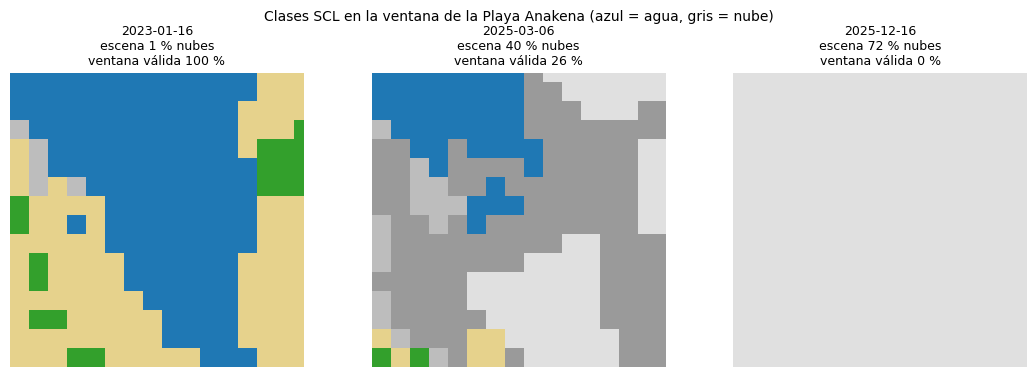

In [17]:
excluir = [0, 1, 3, 8, 9, 10]  # sin datos, saturado, sombra de nube, nube media, nube alta y cirrus (tabla de arriba)
valida = ~ventana["SCL"].isin(excluir)  # True donde el píxel es válido
fraccion_valida = valida.mean(["x", "y"]).to_series()
orden = fraccion_valida.sort_values(ascending=False)
elegidas = [orden.index[0], orden.index[len(orden) // 2], orden.index[-1]]

colores_scl = ["#000000", "#ff0000", "#4d4d4d", "#8b4513", "#33a02c", "#e6d28c", "#1f78b4", "#bdbdbd", "#9a9a9a", "#e0e0e0", "#a6cee3", "#ffffff"]
cmap_scl = ListedColormap(colores_scl)
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8))
for eje, fecha in zip(ejes, elegidas):
    imagen = ventana["SCL"].sel(time=fecha).values
    eje.imshow(imagen, cmap=cmap_scl, vmin=-0.5, vmax=11.5)
    nubes_fecha = float(ventana["nubes_escena"].sel(time=fecha))
    eje.set_title(f"{pd.Timestamp(fecha):%Y-%m-%d}\nescena {nubes_fecha:.0f} % nubes\nventana válida {100 * fraccion_valida[fecha]:.0f} %", fontsize=9)
    eje.axis("off")
plt.suptitle("Clases SCL en la ventana de la Playa Anakena (azul = agua, gris = nube)", fontsize=10)
plt.tight_layout()
plt.show()

**Paso 2: aplicar la máscara y convertir a reflectancia.** Los píxeles inválidos pasan a NaN. Luego `reflectancia_sentinel2` aplica `DN * 0.0001 + offset`, con el offset de **cada fecha** (la coordenada `offset_reflectancia`). Por eso se convierte **antes** de combinar fechas.

**Paso 3: los índices.** Con la reflectancia calculamos, con aritmética de bandas (cada banda es un `DataArray` y se opera directamente): NDWI de McFeeters (agua, `(B03 - B08) / (B03 + B08)`), NDCI (clorofila, `(B05 - B04) / (B05 + B04)`), NDVI (vegetación, `(B08 - B04) / (B08 + B04)`) y la reflectancia roja B04 (turbidez), que se usa tal cual. Una reflectancia válida es mayor o igual que 0, así que cada índice queda entre -1 y 1; si en un píxel ambas bandas valen 0 la división es 0 / 0 y el resultado es NaN.

In [18]:
espectrales = ventana[["B03", "B04", "B05", "B08"]]
enmascarada = espectrales.where(valida)  # píxeles con nube, sombra, cirrus o sin dato -> NaN
refl = reflectancia_sentinel2(enmascarada)  # DN * 0.0001 + offset de cada fecha
indices = xr.Dataset({
    "NDWI_AGUA": (refl["B03"] - refl["B08"]) / (refl["B03"] + refl["B08"]),  # verde y NIR
    "NDCI": (refl["B05"] - refl["B04"]) / (refl["B05"] + refl["B04"]),  # borde rojo y rojo
    "NDVI": (refl["B08"] - refl["B04"]) / (refl["B08"] + refl["B04"]),  # NIR y rojo
    "B04": refl["B04"],  # reflectancia roja
})
print("Variables:", list(indices.data_vars))
print(f"Reflectancia roja de la ventana, fecha más despejada: mediana {float(refl['B04'].sel(time=elegidas[0]).median()):.4f}")

Variables: ['NDWI_AGUA', 'NDCI', 'NDVI', 'B04']
Reflectancia roja de la ventana, fecha más despejada: mediana 0.1048


Una fecha, un número: la **mediana de la ventana** (los píxeles dentro de los 150 m del punto que no están enmascarados). Si menos de la mitad de la ventana quedó libre de nubes, la fecha se conserva pero su valor queda en NaN, para que el hueco se vea.

## 5. La serie de todos los puntos

`construir_series` hace estos mismos pasos para los seis puntos y entrega una **tabla ancha**: una fila por punto y fecha.

* `ndwi`, `ndci`, `b04` y `ndvi`: la mediana de la ventana.
* `nubes_escena`: las nubes de la escena completa (el filtro del catálogo).
* `pixeles_validos`: la fracción de la ventana que pasó la máscara SCL (lo que pasa en **tu** punto).
* `offset_reflectancia`: el offset aplicado a esa fecha.

In [19]:
serie = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5)
print(f"{len(serie)} filas, {serie['fecha'].nunique()} fechas distintas")
serie.head(8)

1287 filas, 215 fechas distintas


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-01 17:31:19.024,NaN,NaN,NaN,NaN,6.946093,0.466006,706,-0.1
1,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-06 17:31:21.024,NaN,NaN,NaN,NaN,17.927060,0.424929,706,-0.1
2,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-11 17:31:19.024,NaN,NaN,NaN,NaN,42.050928,0.000000,706,-0.1
3,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-16 17:31:21.024,0.269069,0.026047,0.07370,-0.095746,1.441644,0.532578,706,-0.1
4,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-21 17:31:19.024,-0.137846,0.086537,0.08485,0.129281,4.712525,0.849858,706,-0.1
5,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-26 17:31:21.024,NaN,NaN,NaN,NaN,2.311869,0.000000,706,-0.1
6,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-01-31 17:31:19.024,NaN,NaN,NaN,NaN,5.147588,0.087819,706,-0.1
7,bahía_perouse,Bahía de La Pérouse,bahía,-27.087642,-109.297931,2023-02-05 17:31:21.024,-0.045466,0.112727,0.07350,0.085734,8.886284,0.983003,706,-0.1


`resumen_validez` cuenta, por punto, las fechas con cobertura y las fechas que aportan un valor útil:

In [20]:
resumen_validez(serie)

,nombre,fechas,fechas_validas,porcentaje_valido,primera_valida,ultima_valida,nubes_escena_media,pixeles_validos_medio
id,,,,,,,,
bahía_perouse,Bahía de La Pérouse,214,90,42.0,2023-01-16 17:31:21.024,2025-12-31 17:31:31.025,40.6,0.45
hanga_nui,Hanga Nui,215,79,37.0,2023-01-01 17:31:19.024,2025-12-31 17:31:31.025,40.8,0.37
ovahe,Ovahe,214,82,38.0,2023-01-01 17:31:19.024,2025-12-11 17:31:31.025,40.6,0.40
playa_anakena,Playa Anakena,214,77,36.0,2023-01-16 17:31:21.024,2025-12-11 17:31:31.025,40.6,0.39
pto_buceo,Centro de Buceo,215,67,31.0,2023-01-06 17:31:21.024,2025-12-11 17:31:31.025,40.8,0.37
vinapu,Vinapu,215,53,25.0,2023-01-06 17:31:21.024,2025-12-11 17:31:31.025,40.8,0.25


## 6. Filtro de escena frente a máscara SCL: lo medimos

Con una sola carga (de hasta 100 % de nubes) podemos simular cuatro límites de nubes de escena, **con** y **sin** máscara SCL. Para "sin máscara" volvemos a llamar a `construir_series` con `excluir=[]` (no se descarta ninguna clase SCL; solo se quitan los píxeles sin dato).

Contamos las **fechas válidas** (con NDWI calculado) sumando los seis puntos.

In [21]:
sin_scl = construir_series(ventanas, puntos, radio_m=RADIO_M, fraccion_minima=0.5, excluir=[])

filas = []
for limite in (100, 60, 30, 10):
    for nombre, tabla in (("sin máscara SCL", sin_scl), ("con máscara SCL", serie)):
        sub = tabla[tabla["nubes_escena"] <= limite]
        filas.append({"límite de nubes de escena (%)": limite, "máscara": nombre,
                      "fechas": len(sub), "fechas válidas": int(sub["ndwi"].notna().sum())})
comparacion = pd.DataFrame(filas)
ancho = comparacion.pivot(index="límite de nubes de escena (%)", columns="máscara", values=["fechas", "fechas válidas"])
ancho = ancho.sort_index(ascending=False)
ancho

fechas                  fechas válidas  \
máscara                       con máscara SCL sin máscara SCL con máscara SCL   
límite de nubes de escena (%)                                                   
100                                      1287            1287             448   
60                                        900             900             435   
30                                        591             591             352   
10                                        258             258             192   

                                               
máscara                       sin máscara SCL  
límite de nubes de escena (%)                  
100                                      1280  
60                                        900  
30                                        591  
10                                        258

Lo importante está en la diferencia entre las dos columnas de *fechas válidas*. Sin máscara casi todas las fechas parecen válidas, **incluso las nubladas**: una nube es un píxel brillante con valores "razonables", no un dato faltante. La máscara SCL reconoce esas fechas y las deja en NaN.

¿Cuántas de las fechas "válidas sin máscara" tienen en realidad más de la mitad de su ventana tapada? Son las fechas **contaminadas**: si las dejaras, entrarían nubes a tu serie.

In [22]:
unidas = sin_scl.merge(serie, on=["id", "fecha"], suffixes=("_sin", "_con"))
unidas["contaminada"] = unidas["ndwi_sin"].notna() & unidas["ndwi_con"].isna()
filas = []
for limite in (100, 60, 30, 10):
    sub = unidas[unidas["nubes_escena_sin"] <= limite]
    filas.append({"límite de nubes de escena (%)": limite,
                  "fechas válidas sin máscara": int(sub["ndwi_sin"].notna().sum()),
                  "de ellas, contaminadas": int(sub["contaminada"].sum()),
                  "% de píxeles que quita la máscara": round(100 * (1 - sub["pixeles_validos_con"].mean()), 1)})
pd.DataFrame(filas).set_index("límite de nubes de escena (%)")

,fechas válidas sin máscara,"de ellas, contaminadas",% de píxeles que quita la máscara
límite de nubes de escena (%),,,
100,1280,832,62.799999
60,900,465,48.900002
30,591,239,38.000000
10,258,66,24.500000


Así se ve la contaminación en el NDWI de los puntos de agua: las fechas contaminadas (sin máscara) se alejan de las válidas porque están midiendo nube.

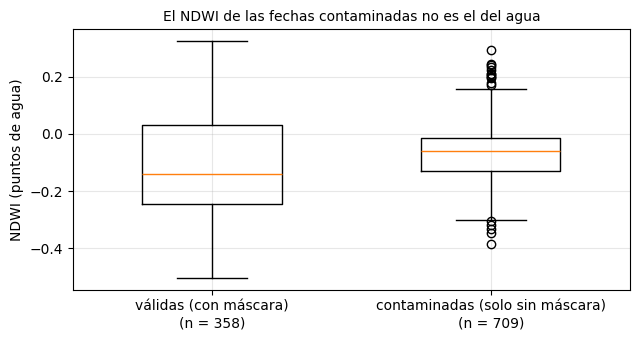

In [23]:
agua = unidas[unidas["tipo_sin"].isin(["bahia", "playa", "rompiente", "puerto"])]
grupos = {"válidas (con máscara)": agua.loc[agua["ndwi_con"].notna(), "ndwi_con"],
          "contaminadas (solo sin máscara)": agua.loc[agua["contaminada"], "ndwi_sin"]}
fig, eje = plt.subplots(figsize=(6.5, 3.5))
eje.boxplot(list(grupos.values()), tick_labels=[f"{k}\n(n = {len(v)})" for k, v in grupos.items()], widths=0.5)
eje.set_ylabel("NDWI (puntos de agua)")
eje.set_title("El NDWI de las fechas contaminadas no es el del agua", fontsize=10)
eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura.**

* El **filtro de escena** descarta fechas completas y es barato, pero ciego a tu punto. Con límites bajos (10 %) casi no hay fechas contaminadas, pero tampoco quedan muchas fechas: en invierno son pocas.
* La **máscara SCL** actúa píxel por píxel. Con límites altos de nubes es la que evita que la nube entre en la serie y conserva fechas despejadas en el punto aunque la escena esté nublada en otro lado.
* Usa **las dos**: un filtro de escena laxo (60 % en el respaldo) para no cargar fechas inútiles y la máscara SCL para el resto.
* Estas cifras son de tres meses de invierno. En verano las nubes son menos y la diferencia se achica.

**Tu turno 2.** Repite la comparación excluyendo además la clase 7 (nube de probabilidad baja o sin clasificar) y la 2 (áreas oscuras). Se pasan como códigos a `excluir`: la lista por defecto es `("sin_datos", "saturado", "sombra_nube", "nube_media", "nube_alta", "cirrus")` y puedes agregarle números. ¿Cambia el número de fechas válidas? ¿Qué pasa con el humedal?

## 7. Guardar la serie en parquet con metadatos (el momento FAIR)

Una tabla suelta en la memoria de Colab se pierde al cerrar la sesión y nadie sabe de dónde salió. En **parquet** la tabla conserva sus tipos y los **metadatos viajan dentro del mismo archivo**: título, descripción, fuente, licencia, parámetros y qué significa cada columna. Es el paso que vuelve tu serie *encontrable, accesible, interoperable y reutilizable*: este archivo es el que pasa a los bloques siguientes.

In [24]:
metadatos = {
    "titulo": f"Series temporales Sentinel-2 en puntos de agua y costa de Rapa Nui ({FECHAS[0]} a {FECHAS[1]})",
    "descripcion": ("Mediana, en una ventana circular de 150 m de radio alrededor de cada punto, del NDWI de McFeeters (B03 y B08), "
                    "el NDCI (B05 y B04), la reflectancia roja B04 y el NDVI (B08 y B04) de Sentinel-2 L2A. Píxeles con nubes, "
                    "sombras, cirros, saturados o sin dato (SCL) descartados antes de resumir; las fechas con menos de la mitad "
                    "de la ventana válida tienen los índices en NaN."),
    "fuente": "ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)",
    "licencia": "Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).",
    "periodo": f"{FECHAS[0]} a {FECHAS[1]}",
    "generado": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "parametros": {"nubes_max_escena": 100, "radio_m": RADIO_M, "estadistico": "mediana", "fraccion_minima_pixeles_validos": 0.5,
                   "resolucion_m": 10, "crs": "UTM de los puntos (EPSG:32718)", "catalogo": "planetary"},
    "columnas": {
        "id": "identificador del punto", "nombre": "nombre del punto", "tipo": "tipo de cobertura",
        "lat": "latitud, grados (EPSG:4326)", "lon": "longitud, grados (EPSG:4326)", "fecha": "fecha y hora UTC de la toma",
        "ndwi": "(B03 - B08) / (B03 + B08), adimensional, positivo sobre agua",
        "ndci": "(B05 - B04) / (B05 + B04), adimensional, sube con la clorofila",
        "b04": "reflectancia roja (0 a 1), sube con la turbidez",
        "ndvi": "(B08 - B04) / (B08 + B04), adimensional",
        "nubes_escena": "% de nubes de la escena completa (eo:cloud_cover)",
        "pixeles_validos": "fracción (0 a 1) de la ventana que pasó la máscara SCL",
        "n_pixeles": "píxeles de la ventana",
        "offset_reflectancia": "offset aplicado a esa fecha (0 o -0.1), según baseline y catálogo"},
}
archivo = Path("mi_serie_sentinel2.rapa_nui.parquet")  # en Colab queda en /content (panel de archivos de la izquierda)
guardar_series(serie, archivo, metadatos)
print(f"Guardado: {archivo} ({archivo.stat().st_size / 1024:.0f} kB)")

Guardado: mi_serie_sentinel2.rapa_nui.parquet (36 kB)


Para comprobar que el archivo se entiende sin este cuaderno, léelo de vuelta junto con sus metadatos:

In [25]:
recuperada = pd.read_parquet(archivo)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
leidos = {k.decode(): v.decode() for k, v in pq.read_schema(archivo).metadata.items() if k != b"pandas"}
print(recuperada.dtypes.to_string())
print("\nMetadatos dentro del archivo:", ", ".join(leidos))
print("Título:", leidos["titulo"])

id                             object
nombre                         object
tipo                           object
lat                           float64
lon                           float64
fecha                  datetime64[ns]
ndwi                          float64
ndci                          float64
b04                           float64
ndvi                          float64
nubes_escena                  float64
pixeles_validos               float32
n_pixeles                       int64
offset_reflectancia           float64

Metadatos dentro del archivo: titulo, descripcion, fuente, licencia, periodo, generado, parametros, columnas
Título: Series temporales Sentinel-2 en puntos de agua y costa de Rapa Nui (2023-01-01 a 2026-01-01)


**Tu turno 3.** En Colab, descarga el parquet (menú de archivos de la izquierda, clic derecho, *Descargar*) y ábrelo con otra herramienta, por ejemplo con `pandas.read_parquet` en tu computador. ¿Qué metadato agregarías para que un tercero lo pueda reutilizar sin preguntarte nada? (Una pista: el bloque 1 ya te dio la respuesta.)

## 8. La serie de 3 años de respaldo y su gráfico

In [26]:
respaldo = pd.read_parquet(DATOS / "mi_serie_sentinel2.rapa_nui.parquet")
print(f"Respaldo: {len(respaldo)} filas, {respaldo['fecha'].min():%Y-%m-%d} a {respaldo['fecha'].max():%Y-%m-%d}")

variables = ["ndwi", "ndci", "b04", "ndvi", "pixeles_validos"]
nuestra = serie[serie["nubes_escena"] <= 60].set_index(["id", "fecha"]).sort_index()
suya = respaldo[(respaldo["fecha"] >= FECHAS[0]) & (respaldo["fecha"] <= f"{FECHAS[1]} 23:59")].set_index(["id", "fecha"]).sort_index()
comunes = nuestra.index.intersection(suya.index)
diferencia = (nuestra.loc[comunes, variables] - suya.loc[comunes, variables]).abs().max()
print(f"Filas en común: {len(comunes)} (nuestra: {len(nuestra)}, respaldo: {len(suya)})")
print("Diferencia máxima por variable:", diferencia.round(6).to_dict())

Respaldo: 1287 filas, 2023-01-01 a 2025-12-31
Filas en común: 900 (nuestra: 900, respaldo: 1287)
Diferencia máxima por variable: {'ndwi': 0.0, 'ndci': 0.0, 'b04': 0.0, 'ndvi': 0.0, 'pixeles_validos': 0.0}


Ahora el gráfico de las cuatro variables con `plotly`: un panel por variable y un color por punto. Los marcadores son las **observaciones** (no hay datos entre ellos). Es interactivo: pasa el mouse sobre un marcador para ver su valor, haz clic en un nombre de la leyenda para ocultar o mostrar un punto, arrastra para acercar y haz doble clic para volver a la vista completa.

In [27]:
etiquetas = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)", "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

# plotly pide una fila por observación y variable ("formato largo"); las fechas sin valor (NaN) se omiten
largo = respaldo.melt(id_vars=["nombre", "fecha"], value_vars=list(etiquetas), var_name="variable", value_name="valor")
largo["variable"] = largo["variable"].map(etiquetas)
largo = largo.dropna(subset=["valor"])

fig = px.line(largo, x="fecha", y="valor", color="nombre", facet_row="variable", markers=True,
              category_orders={"variable": list(etiquetas.values())}, color_discrete_sequence=PALETA,
              title="Series Sentinel-2 por punto, enero de 2024 a enero de 2026", height=900,
              labels={"fecha": "Fecha", "valor": "", "nombre": "Punto"})
fig.update_yaxes(matches=None)  # cada panel con su propia escala
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # el título de cada panel: "variable=NDWI" -> "NDWI"
fig.show()

**Cómo mirarlo.** El humedal (NDVI alto, NDWI muy negativo) separa tierra de agua. Entre los puntos de agua, la pluma del Biobío tiene la mediana de reflectancia roja más alta. En el bloque 5 medimos todo esto con números; en el 6 hacemos más gráficos interactivos.

**Tu turno 4.** Con la serie de respaldo: ¿qué punto tiene menos fechas válidas de NDWI? ¿Qué mes tiene menos fechas en total entre los seis puntos? Usa `resumen_validez(respaldo)` y `respaldo.groupby(respaldo["fecha"].dt.to_period("M")).size()`.

In [ ]:
# Tu turno 4
resumen_validez(respaldo)

## Cierre

* Una serie por punto se construye cargando **ventanas pequeñas**, no la caja completa.
* El offset de reflectancia se decide **por fecha** (`agregar_offset`); nunca se fija a mano.
* Filtro de escena y máscara SCL no son lo mismo: la máscara es la que protege tu punto. Úsalas juntas.
* El parquet con metadatos es el momento FAIR: el archivo se explica solo y pasa al bloque 5.

Entregable del día: este cuaderno con tu serie guardada en parquet.

In [ ]:
# Limpieza: borra el parquet de práctica si no lo necesitas (en Colab desaparece al cerrar la sesión)
# archivo.unlink()